In [1]:
import os, glob, random
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from torchvision.transforms import functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Torch:", torch.__version__)

Device: cuda
Torch: 2.11.0+cu128


In [2]:
# 1) Locate the attached prepared dataset
DATA_ROOT = None
for root, dirs, files in os.walk("/kaggle/input"):
    if all(d in dirs for d in ["train", "val", "test"]):
        if os.path.isdir(os.path.join(root, "test", "images")):
            DATA_ROOT = root
            break

if DATA_ROOT is None:
    # fallback: locate any test/images directory
    for root, dirs, files in os.walk("/kaggle/input"):
        if os.path.basename(root) == "images" and os.path.basename(os.path.dirname(root)) == "test":
            DATA_ROOT = os.path.dirname(os.path.dirname(root))
            break

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Prepared dataset not found. Use Kaggle Add Input and ensure it contains test/images."
    )

TEST_IMG_DIR = os.path.join(DATA_ROOT, "test", "images")
print("Dataset root:", DATA_ROOT)
print("Test images folder:", TEST_IMG_DIR)

# 2) Locate the existing trained Faster R-CNN checkpoint
# Prefer the final .pth file; the training notebook's checkpoint may be a .txt-named torch file.
candidates = []
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        low = f.lower()
        if low.endswith((".pth", ".pt", ".ckpt")) or "latest_phase2" in low:
            candidates.append(os.path.join(root, f))

preferred = [p for p in candidates if "faster_rcnn_epoch_10_final" in os.path.basename(p).lower()]
if not preferred:
    preferred = [p for p in candidates if "latest_phase2" in os.path.basename(p).lower()]
if not preferred:
    preferred = [p for p in candidates if p.lower().endswith((".pth", ".pt", ".ckpt"))]

print("Checkpoint candidates:")
for p in candidates:
    print(" -", p)

if not preferred:
    raise FileNotFoundError(
        "No trained checkpoint found under /kaggle/input. "
        "Save your existing checkpoint as a Kaggle Dataset and attach it with Add Input."
    )

CHECKPOINT_PATH = preferred[0]
print("\nUsing checkpoint:", CHECKPOINT_PATH)

Dataset root: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset
Test images folder: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/images
Checkpoint candidates:
 - /kaggle/input/datasets/sharminaktermukta/10-epoch-faster-cnn/faster_rcnn_epoch_10_FINAL.pth

Using checkpoint: /kaggle/input/datasets/sharminaktermukta/10-epoch-faster-cnn/faster_rcnn_epoch_10_FINAL.pth


In [3]:
# 3) Rebuild the same Faster R-CNN architecture and load trained weights
CLASSES = [
    "Car", "Bus", "Truck", "Motorcycle", "Bicycle",
    "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"
]
NUM_CLASSES = len(CLASSES) + 1  # background + 9 classes

model = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict)
model.to(device)
model.eval()
print("Existing trained Faster R-CNN weights loaded successfully.")

Existing trained Faster R-CNN weights loaded successfully.


In [4]:
# 4) PCU rules copied from your EfficientDet-D3 pipeline
class_mapping = {i + 1: name for i, name in enumerate(CLASSES)}
pcu_weights = {
    "Car": 1.0,
    "Bus": 3.0,
    "Truck": 3.0,
    "Mini-Truck": 1.5,
    "CNG": 0.75,
    "Rickshaw": 0.8,
    "Motorcycle": 0.4,
    "Bicycle": 0.3,
    "Pedestrian": 0.0
}


CONF_THRESHOLD = 0.30
LOW_UPPER = 8.45
MEDIUM_UPPER = 15.8

def analyze_road_pcu(image_path, draw=True):
    image = Image.open(image_path).convert("RGB")
    image_np = np.array(image)
    width, height = image.size
    tensor = TF.to_tensor(image).to(device)

    with torch.no_grad():
        pred = model([tensor])[0]

    boxes = pred["boxes"].detach().cpu().numpy()
    scores = pred["scores"].detach().cpu().numpy()
    labels = pred["labels"].detach().cpu().numpy()

    counts = {name: 0 for name in CLASSES}
    detections = []
    total_pcu = 0.0

    for box, score, label in zip(boxes, scores, labels):
        if float(score) < CONF_THRESHOLD:
            continue
        name = class_mapping.get(int(label))
        if name is None:
            continue
        x1, y1, x2, y2 = map(float, box)
        x1, x2 = max(0, min(x1, width - 1)), max(0, min(x2, width - 1))
        y1, y2 = max(0, min(y1, height - 1)), max(0, min(y2, height - 1))
        if x2 <= x1 or y2 <= y1:
            continue
        counts[name] += 1
        total_pcu += pcu_weights[name]
        detections.append((x1, y1, x2, y2, float(score), name))

    if total_pcu < LOW_UPPER:
        level = "Low"
    elif total_pcu <= MEDIUM_UPPER:
        level = "Medium"
    else:
        level = "High"

    if draw:
        fig, ax = plt.subplots(figsize=(13, 8))
        ax.imshow(image_np)
        for x1, y1, x2, y2, score, name in detections:
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                linewidth=2, edgecolor="deepskyblue", facecolor="none"
            ))
            ax.text(x1, max(0, y1-5), f"{name} {score:.2f}",
                    color="white", fontsize=9,
                    bbox=dict(facecolor="blue", alpha=0.7, edgecolor="none"))
        ax.set_title(f"Faster R-CNN | Total PCU: {total_pcu:.2f} | Congestion: {level}")
        ax.axis("off")
        plt.tight_layout()
        plt.show()

    return {
        "image": os.path.basename(image_path),
        "detected_objects": len(detections),
        **{f"{name}_count": counts[name] for name in CLASSES},
        "total_pcu": round(total_pcu, 3),
        "congestion_level": level
    }

print("PCU inference function is ready.")

PCU inference function is ready.



========== Low CONGESTION ==========
Image: frame103_jpg.rf.2cd03eb8cf570f1091f1399c426714dd.jpg
Total PCU: 6.0


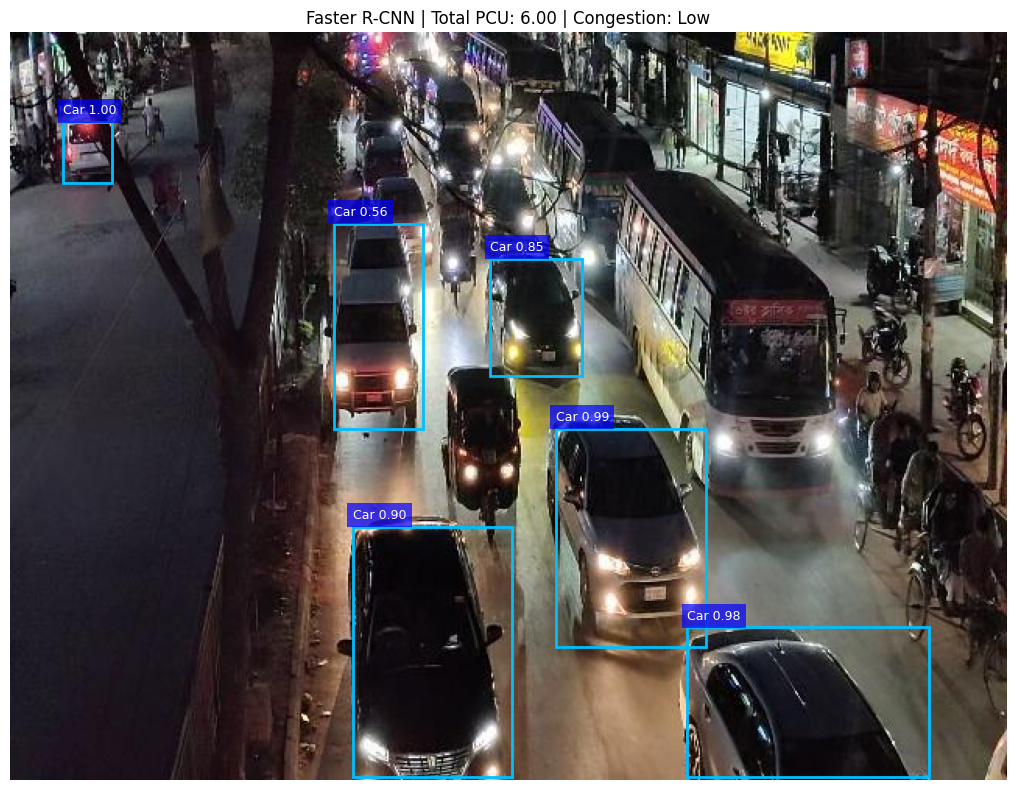


========== Medium CONGESTION ==========
Image: frame101_jpg.rf.1199a87d43701d3b1db8a5a985f80640.jpg
Total PCU: 10.4


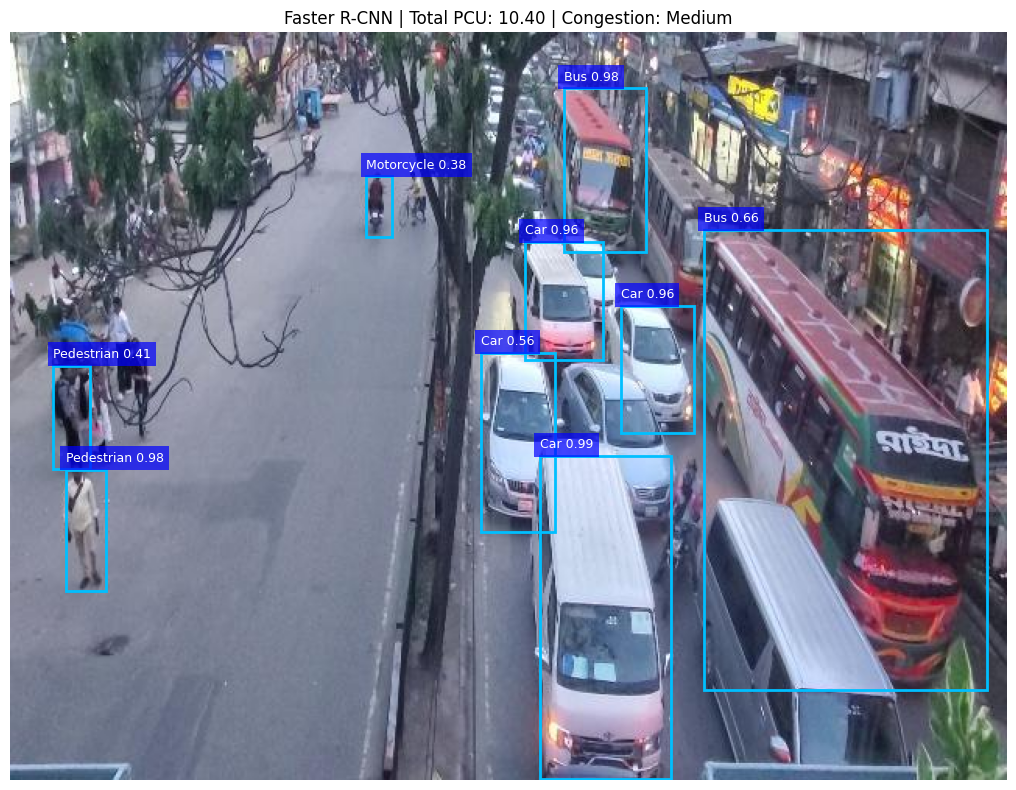


========== High CONGESTION ==========
Image: frame0_jpg.rf.2bdb52fd96f81bc52a55e5b5ce1ab3fd.jpg
Total PCU: 16.85


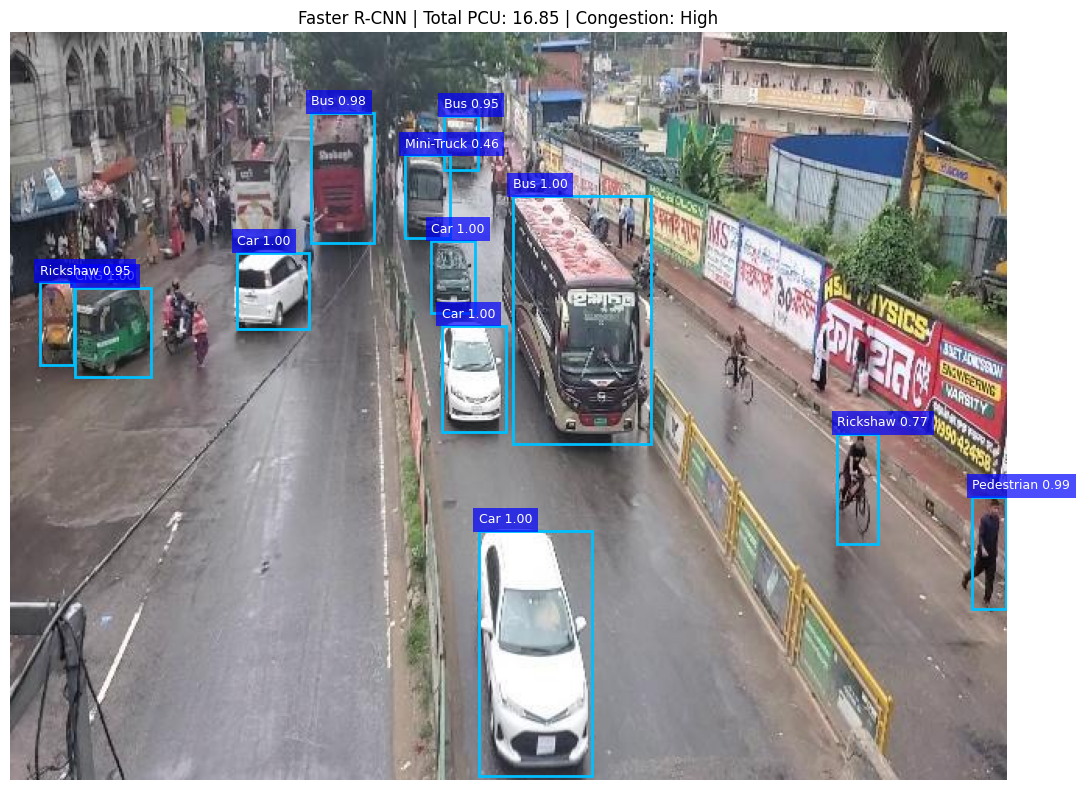

,image,detected_objects,Car_count,Bus_count,Truck_count,Motorcycle_count,Bicycle_count,Rickshaw_count,Mini-Truck_count,CNG_count,Pedestrian_count,total_pcu,congestion_level
0,frame103_jpg.rf.2cd03eb8cf570f1091f1399c426714...,6,6,0,0,0,0,0,0,0,0,6.00,Low
1,frame101_jpg.rf.1199a87d43701d3b1db8a5a985f806...,9,4,2,0,1,0,0,0,0,2,10.40,Medium
2,frame0_jpg.rf.2bdb52fd96f81bc52a55e5b5ce1ab3fd...,12,4,3,0,0,0,2,1,1,1,16.85,High


In [5]:
# ==========================================================
# Show one sample image for Low, Medium and High congestion
# ==========================================================

extensions = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]
test_images = []

for ext in extensions:
    test_images.extend(glob.glob(os.path.join(TEST_IMG_DIR, ext)))

test_images = sorted(set(test_images))

if not test_images:
    raise FileNotFoundError("No test images found in " + TEST_IMG_DIR)

samples = {
    "Low": None,
    "Medium": None,
    "High": None
}

# Search until one image is found for each congestion level
for img_path in test_images:
    result = analyze_road_pcu(img_path, draw=False)

    level = result["congestion_level"]

    if samples[level] is None:
        samples[level] = (img_path, result)

    # Stop if all three are found
    if all(v is not None for v in samples.values()):
        break

# Display one image from each category
summary = []

for level in ["Low", "Medium", "High"]:

    if samples[level] is None:
        print(f"\n❌ No {level} congestion image found.")
        continue

    img_path, result = samples[level]

    print(f"\n========== {level} CONGESTION ==========")
    print("Image:", os.path.basename(img_path))
    print("Total PCU:", result["total_pcu"])

    # Draw prediction with bounding boxes
    analyze_road_pcu(img_path, draw=True)

    summary.append(result)

# Summary table
summary_df = pd.DataFrame(summary)
summary_df

In [6]:
# ==========================================================
# Run Faster R-CNN PCU analysis on ALL test images
# ==========================================================

import os
import glob
import pandas as pd
from tqdm.auto import tqdm

extensions = ["*.jpg", "*.jpeg", "*.png",
              "*.JPG", "*.JPEG", "*.PNG"]

test_images = []

for ext in extensions:
    test_images.extend(
        glob.glob(os.path.join(TEST_IMG_DIR, ext))
    )

test_images = sorted(set(test_images))

if not test_images:
    raise FileNotFoundError(
        f"No test images found in: {TEST_IMG_DIR}"
    )

all_results = []

for img_path in tqdm(test_images, desc="Analyzing test images"):
    result = analyze_road_pcu(img_path, draw=False)

    # Keep image filename in the results
    result["image_name"] = os.path.basename(img_path)
    all_results.append(result)

results_df = pd.DataFrame(all_results)

# Save results
output_path = "/kaggle/working/faster_rcnn_pcu_results.csv"
results_df.to_csv(output_path, index=False)

print("Total test images:", len(results_df))
print("\nCongestion level counts:")
print(results_df["congestion_level"].value_counts())

print("\nResults saved to:", output_path)

display(results_df.head(10))

Analyzing test images:   0%|          | 0/2368 [00:00<?, ?it/s]

Total test images: 2368

Congestion level counts:
congestion_level
High      1181
Medium     885
Low        302
Name: count, dtype: int64

Results saved to: /kaggle/working/faster_rcnn_pcu_results.csv


,image,detected_objects,Car_count,Bus_count,Truck_count,Motorcycle_count,Bicycle_count,Rickshaw_count,Mini-Truck_count,CNG_count,Pedestrian_count,total_pcu,congestion_level,image_name
0,frame0_jpg.rf.2bdb52fd96f81bc52a55e5b5ce1ab3fd...,12,4,3,0,0,0,2,1,1,1,16.85,High,frame0_jpg.rf.2bdb52fd96f81bc52a55e5b5ce1ab3fd...
1,frame0_jpg.rf.47f88bfa8857bb079cdaaffe6aa6ecd2...,23,7,5,0,1,0,5,0,2,3,27.90,High,frame0_jpg.rf.47f88bfa8857bb079cdaaffe6aa6ecd2...
2,frame0_jpg.rf.9067d8476599d820a5497e7a4933764d...,16,3,4,0,0,0,5,2,2,0,23.50,High,frame0_jpg.rf.9067d8476599d820a5497e7a4933764d...
3,frame0_jpg.rf.b67d0effd101dedad76f7e39e2a02eb9...,25,7,7,0,3,0,5,0,1,2,33.95,High,frame0_jpg.rf.b67d0effd101dedad76f7e39e2a02eb9...
4,frame100_jpg.rf.f5d0a13c14dfb93b6678b392575a33...,17,3,3,0,1,0,5,0,5,0,20.15,High,frame100_jpg.rf.f5d0a13c14dfb93b6678b392575a33...
5,frame101_jpg.rf.1199a87d43701d3b1db8a5a985f806...,9,4,2,0,1,0,0,0,0,2,10.40,Medium,frame101_jpg.rf.1199a87d43701d3b1db8a5a985f806...
6,frame101_jpg.rf.1ad17c9daa9cc9c269a8d09e7ff998...,16,1,2,0,1,0,6,0,2,4,13.70,Medium,frame101_jpg.rf.1ad17c9daa9cc9c269a8d09e7ff998...
7,frame101_jpg.rf.1f2e8106bb6e310470a2f52b2bc578...,25,3,6,0,1,0,4,1,3,7,28.35,High,frame101_jpg.rf.1f2e8106bb6e310470a2f52b2bc578...
8,frame101_jpg.rf.82e582fc10a003180029381a156c7f...,17,2,8,0,2,0,1,0,0,4,27.60,High,frame101_jpg.rf.82e582fc10a003180029381a156c7f...
9,frame101_jpg.rf.cfcec2c89004baef32d683e3cb3e1b...,11,3,2,1,1,0,3,0,1,0,15.55,Medium,frame101_jpg.rf.cfcec2c89004baef32d683e3cb3e1b...


congestion_level
Low        302
Medium     885
High      1181
Name: count, dtype: int64


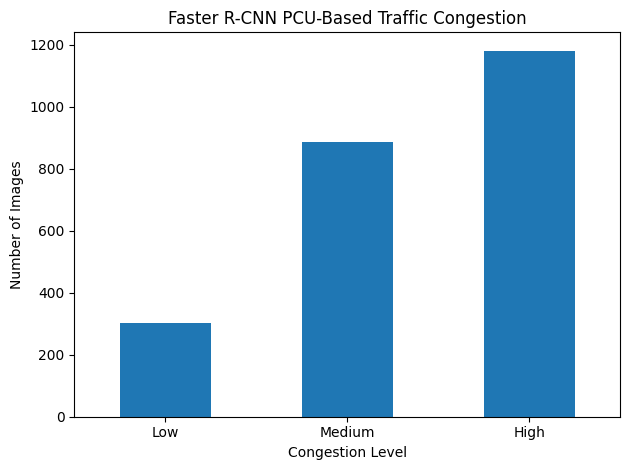

In [7]:
import matplotlib.pyplot as plt

level_counts = (
    results_df["congestion_level"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
)

print(level_counts)

level_counts.plot(kind="bar")
plt.title("Faster R-CNN PCU-Based Traffic Congestion")
plt.xlabel("Congestion Level")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# ==========================================
# CELL 1: CLASS MAPPING AND PCU CONFIGURATION
# ==========================================

CLASSES = [
    "Car",
    "Bus",
    "Truck",
    "Motorcycle",
    "Bicycle",
    "Rickshaw",
    "Mini-Truck",
    "CNG",
    "Pedestrian"
]

class_mapping = {
    i + 1: name for i, name in enumerate(CLASSES)
}

# SAME PCU WEIGHTS FOR ALL MODELS
pcu_weights = {
    "Car": 1.0,
    "Bus": 3.0,
    "Truck": 3.0,
    "Mini-Truck": 1.5,
    "CNG": 0.75,
    "Rickshaw": 0.8,
    "Motorcycle": 0.4,
    "Bicycle": 0.3,
    "Pedestrian": 0.0
}

# SAME CONGESTION THRESHOLDS
LOW_THRESHOLD = 8.45
HIGH_THRESHOLD = 15.80

CONF_THRESHOLD = 0.30

print("Classes:", CLASSES)
print("Class Mapping:", class_mapping)
print("PCU Weights:", pcu_weights)
print("Thresholds:", LOW_THRESHOLD, HIGH_THRESHOLD)

Classes: ['Car', 'Bus', 'Truck', 'Motorcycle', 'Bicycle', 'Rickshaw', 'Mini-Truck', 'CNG', 'Pedestrian']
Class Mapping: {1: 'Car', 2: 'Bus', 3: 'Truck', 4: 'Motorcycle', 5: 'Bicycle', 6: 'Rickshaw', 7: 'Mini-Truck', 8: 'CNG', 9: 'Pedestrian'}
PCU Weights: {'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5, 'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0}
Thresholds: 8.45 15.8


In [9]:
# ==========================================
# CELL 2: FASTER R-CNN PCU ANALYSIS FUNCTION
# ==========================================

def analyze_road_pcu(image_path, draw=False):

    image = Image.open(image_path).convert("RGB")
    image_tensor = to_tensor(image).to(device)

    with torch.no_grad():
        output = model([image_tensor])[0]

    boxes = output["boxes"].detach().cpu().numpy()
    scores = output["scores"].detach().cpu().numpy()
    labels = output["labels"].detach().cpu().numpy()

    total_pcu = 0.0
    class_counts = {name: 0 for name in CLASSES}
    detections = []

    for box, score, label in zip(boxes, scores, labels):

        if score < CONF_THRESHOLD:
            continue

        class_id = int(label)

        if class_id not in class_mapping:
            continue

        class_name = class_mapping[class_id]

        class_counts[class_name] += 1

        # SAME PCU WEIGHTS
        total_pcu += pcu_weights[class_name]

        detections.append({
            "class": class_name,
            "confidence": float(score),
            "box": box.tolist()
        })

    if total_pcu < LOW_THRESHOLD:
        congestion_level = "Low"

    elif total_pcu <= HIGH_THRESHOLD:
        congestion_level = "Medium"

    else:
        congestion_level = "High"

    return {
        "image": image,
        "detections": detections,
        "class_counts": class_counts,
        "total_pcu": total_pcu,
        "congestion_level": congestion_level
    }


print("Updated Faster R-CNN PCU function successfully!")

Updated Faster R-CNN PCU function successfully!


Ground Truth Evaluation:   0%|          | 0/2368 [00:00<?, ?it/s]


========== FASTER R-CNN PCU RESULTS ==========
Total test images: 2368
Accuracy: 63.72%

Classification Report:


,precision,recall,f1-score,support
Low,0.9007,0.3994,0.5534,681.0000
Medium,0.5661,0.5405,0.5530,927.0000
High,0.6232,0.9684,0.7584,760.0000
accuracy,0.6372,0.6372,0.6372,0.6372
macro avg,0.6967,0.6361,0.6216,2368.0000
weighted avg,0.6806,0.6372,0.6190,2368.0000


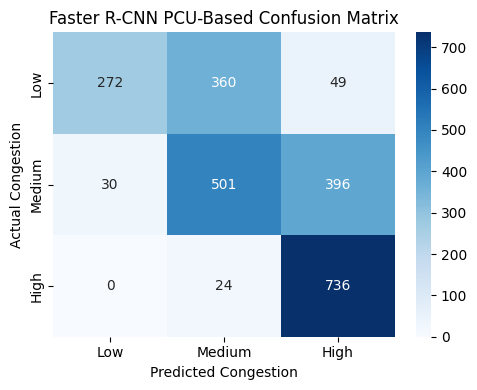


All evaluation files saved successfully!


In [10]:

# ==========================================================
# FINAL: FASTER R-CNN PCU-BASED CONGESTION EVALUATION
# ==========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# 1. Dataset label directory
TEST_LABEL_DIR = os.path.join(DATA_ROOT, "test", "labels")

if not os.path.isdir(TEST_LABEL_DIR):
    raise FileNotFoundError(
        f"Test labels folder not found: {TEST_LABEL_DIR}"
    )

# 2. Check updated prediction results
if "results_df" not in globals():
    raise NameError("Run the updated Faster R-CNN inference cell first.")

required_columns = ["image_name", "congestion_level"]

for col in required_columns:
    if col not in results_df.columns:
        raise ValueError(
            f"Missing column: {col}. "
            "Rerun the ALL test images inference cell."
        )

# 3. Ground Truth PCU calculation
def calculate_gt_pcu(label_path):

    total_pcu = 0.0

    with open(label_path, "r") as f:
        for line in f:

            values = line.strip().split()

            if len(values) < 5:
                continue

            # YOLO annotation IDs are zero-based
            class_id = int(float(values[0]))

            if class_id < 0 or class_id >= len(CLASSES):
                raise ValueError(
                    f"Invalid class ID {class_id}: {label_path}"
                )

            class_name = CLASSES[class_id]
            total_pcu += pcu_weights[class_name]

    return total_pcu


def get_congestion(pcu):

    if pcu < LOW_THRESHOLD:
        return "Low"

    elif pcu <= HIGH_THRESHOLD:
        return "Medium"

    else:
        return "High"


# 4. Match predictions with ground-truth annotations
ground_truth = []
predictions = []
gt_pcu_values = []

missing_labels = []

for _, row in tqdm(
    results_df.iterrows(),
    total=len(results_df),
    desc="Ground Truth Evaluation"
):

    image_name = row["image_name"]
    label_name = os.path.splitext(image_name)[0] + ".txt"
    label_path = os.path.join(TEST_LABEL_DIR, label_name)

    if not os.path.isfile(label_path):
        missing_labels.append(label_name)
        continue

    gt_pcu = calculate_gt_pcu(label_path)

    gt_level = get_congestion(gt_pcu)
    pred_level = row["congestion_level"]

    gt_pcu_values.append(gt_pcu)
    ground_truth.append(gt_level)
    predictions.append(pred_level)

if missing_labels:
    raise FileNotFoundError(
        f"{len(missing_labels)} annotation files missing. "
        f"Examples: {missing_labels[:5]}"
    )

if len(ground_truth) != len(results_df):
    raise ValueError("Ground truth and prediction counts do not match.")

# 5. Confusion Matrix
labels = ["Low", "Medium", "High"]

cm = confusion_matrix(
    ground_truth,
    predictions,
    labels=labels
)

# 6. Accuracy
accuracy = accuracy_score(ground_truth, predictions)

print("\n========== FASTER R-CNN PCU RESULTS ==========")
print("Total test images:", len(ground_truth))
print(f"Accuracy: {accuracy * 100:.2f}%")

# 7. Classification Report
report = classification_report(
    ground_truth,
    predictions,
    labels=labels,
    target_names=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nClassification Report:")
display(report_df.round(4))

# 8. Save classification report
report_df.to_csv(
    "/kaggle/working/faster_rcnn_classification_report.csv"
)

# 9. Display Confusion Matrix
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Congestion")
plt.ylabel("Actual Congestion")
plt.title("Faster R-CNN PCU-Based Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/faster_rcnn_congestion_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Save confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=["Actual Low", "Actual Medium", "Actual High"],
    columns=["Predicted Low", "Predicted Medium", "Predicted High"]
)

cm_df.to_csv(
    "/kaggle/working/faster_rcnn_congestion_confusion_matrix.csv"
)

print("\nAll evaluation files saved successfully!")
